# Notebook 01: Khám phá dữ liệu (EDA) – Instacart Market Basket Analysis

Notebook này **không tạo ra dữ liệu mới**. Đầu ra của tiền xử lý vẫn là 4 file trong `data/processed/`.
Mục tiêu ở đây là *hiểu* dữ liệu và *biện luận* cho các quyết định tiền xử lý:

1. Tổng quan 6 bảng dữ liệu gốc.
2. Kiểm tra chất lượng dữ liệu (lý do của các bước lọc trong `src/preprocess.py`).
3. Phân bố kích thước giỏ hàng (lý do lọc giỏ ≥ 2 món).
4. Sản phẩm phổ biến và hiện tượng "đuôi dài" (cơ sở chọn ngưỡng `min_support` cho benchmark).
5. Mẫu 10k / 50k / 100k có đại diện cho toàn bộ dữ liệu không.
6. Phân tích ở mức kệ hàng.
7. Hạn chế: một khách hàng đóng góp nhiều đơn.

Biểu đồ được lưu vào `results/figures/` để dùng cho báo cáo.

> **Quy ước:** *support* của một món = tỷ lệ giỏ hàng chứa món đó. Để so sánh được với kết quả khai phá,
> support "tổng thể" được tính trên **các đơn prior có ≥ 2 món**, đúng như quy tắc lọc của tiền xử lý.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, PercentFormatter

# Chạy được cả khi mở notebook từ thư mục notebooks/ hoặc từ thư mục gốc
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
FIG_DIR = ROOT / 'results' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

MIN_BASKET_SIZE = 2                          # cùng quy tắc với src/preprocess.py
SUPPORTS = [0.05, 0.03, 0.02, 0.01, 0.005]   # cùng các ngưỡng với src/benchmark.py

# Màu: xanh = tổng thể / chuỗi chính, cam = mẫu / phần bị loại
BLUE, ORANGE = '#2a78d6', '#eb6834'
TEXT, TEXT_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': '#bdbcb6', 'axes.labelcolor': TEXT_2, 'text.color': TEXT,
    'axes.titlecolor': TEXT, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'xtick.color': TEXT_2, 'ytick.color': TEXT_2, 'font.size': 10,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False,
    'figure.dpi': 110,
})
pct = lambda decimals=0: PercentFormatter(1, decimals=decimals)


def save(fig, name):
    """Lưu biểu đồ ra results/figures/<name>.png cho báo cáo."""
    fig.savefig(FIG_DIR / f'{name}.png', dpi=160, bbox_inches='tight')

## 1. Tổng quan 6 bảng dữ liệu gốc

Bảng chi tiết đơn hàng rất lớn, nên chỉ đọc 2 cột cần dùng (`order_id`, `product_id`) với kiểu `int32`.
Danh sách cột đầy đủ được lấy từ dòng tiêu đề của từng file.

In [2]:
products = pd.read_csv(RAW_DIR / 'products.csv')
aisles = pd.read_csv(RAW_DIR / 'aisles.csv')
departments = pd.read_csv(RAW_DIR / 'departments.csv')
orders = pd.read_csv(RAW_DIR / 'orders.csv', usecols=['order_id', 'user_id', 'eval_set'],
                     dtype={'order_id': np.int32, 'user_id': np.int32})
op_prior = pd.read_csv(RAW_DIR / 'order_products__prior.csv', usecols=['order_id', 'product_id'],
                       dtype={'order_id': np.int32, 'product_id': np.int32})
n_train_rows = len(pd.read_csv(RAW_DIR / 'order_products__train.csv', usecols=['order_id']))

files = {
    'aisles': ('aisles.csv', len(aisles)),
    'departments': ('departments.csv', len(departments)),
    'products': ('products.csv', len(products)),
    'orders': ('orders.csv', len(orders)),
    'order_products__prior': ('order_products__prior.csv', len(op_prior)),
    'order_products__train': ('order_products__train.csv', n_train_rows),
}
overview = pd.DataFrame([
    {'Bảng': name, 'Số dòng': f'{n:,}',
     'Các cột': ', '.join(pd.read_csv(RAW_DIR / f, nrows=0).columns)}
    for name, (f, n) in files.items()
])
overview

,Bảng,Số dòng,Các cột
0,aisles,134,"aisle_id, aisle"
1,departments,21,"department_id, department"
2,products,"49,688","product_id, product_name, aisle_id, department_id"
3,orders,"3,421,083","order_id, user_id, eval_set, order_number, ord..."
4,order_products__prior,"32,434,489","order_id, product_id, add_to_cart_order, reord..."
5,order_products__train,"1,384,617","order_id, product_id, add_to_cart_order, reord..."


**Nhận xét.** `order_products__prior` là bảng trung tâm (mỗi dòng = "đơn X chứa sản phẩm Y").
Tiền xử lý chỉ cần 3 bảng: `order_products__prior` (đơn chứa món gì), `products` (tên sản phẩm, mã kệ) và `aisles` (tên kệ).
`orders`, `departments` và `order_products__train` không dùng cho khai phá; `orders` chỉ dùng ở mục 7 để xem đơn thuộc khách nào.

## 2. Kiểm tra chất lượng dữ liệu

Mỗi dòng dưới đây tương ứng với một câu hỏi: "có cần xử lý điều này trong tiền xử lý không?"

In [3]:
missing_aisle_ids = aisles.loc[aisles['aisle'] == 'missing', 'aisle_id']
missing_pids = products.loc[products['aisle_id'].isin(missing_aisle_ids), 'product_id']

checks = pd.DataFrame([
    ('Tên sản phẩm bị rỗng', products['product_name'].isna().sum()),
    ('Tên sản phẩm bị trùng (2 mã khác nhau cùng tên)', products['product_name'].duplicated().sum()),
    ('Tên sản phẩm chứa ký tự "|" (dấu phân cách trong file CSV)', products['product_name'].str.contains('|', regex=False).sum()),
    ('Cặp (đơn, sản phẩm) bị lặp trong prior', op_prior.duplicated(['order_id', 'product_id']).sum()),
    ('product_id trong prior không có trong products', (~op_prior['product_id'].isin(products['product_id'])).sum()),
    ('Sản phẩm thuộc kệ "missing"', len(missing_pids)),
    ('Dòng prior chứa sản phẩm thuộc kệ "missing"', op_prior['product_id'].isin(missing_pids).sum()),
], columns=['Kiểm tra', 'Số lượng'])
checks['Số lượng'] = checks['Số lượng'].map('{:,}'.format)
checks

,Kiểm tra,Số lượng
0,Tên sản phẩm bị rỗng,0
1,Tên sản phẩm bị trùng (2 mã khác nhau cùng tên),0
2,"Tên sản phẩm chứa ký tự ""|"" (dấu phân cách tro...",0
3,"Cặp (đơn, sản phẩm) bị lặp trong prior",0
4,product_id trong prior không có trong products,0
5,"Sản phẩm thuộc kệ ""missing""","1,258"
6,"Dòng prior chứa sản phẩm thuộc kệ ""missing""","69,145"


**Nhận xét.**
- Tên sản phẩm không rỗng, không trùng, không chứa `|` → dùng **tên** làm item an toàn, và dấu phân cách `' | '` trong file CSV không gây tách sai.
- Không có cặp (đơn, sản phẩm) lặp → ở mức sản phẩm **không cần bỏ trùng**.
- Mọi `product_id` đều có trong bảng sản phẩm → phép `merge(how='inner')` không làm mất dòng nào.
- Có một nhóm sản phẩm thuộc kệ `missing` (chưa phân loại) → ở **mức kệ hàng** phải loại nhãn này, nếu không sẽ sinh luật vô nghĩa kiểu `{missing} → {fresh fruits}`.

## 3. Phân bố kích thước giỏ hàng

Câu hỏi: lọc bỏ đơn chỉ có 1 món sẽ loại bao nhiêu dữ liệu?

In [4]:
basket_size = op_prior.groupby('order_id').size()
eligible = basket_size[basket_size >= MIN_BASKET_SIZE].index
N_POP = len(eligible)

pd.Series({
    'Tổng số đơn prior': f'{len(basket_size):,}',
    'Đơn có 1 món (bị loại)': f'{(basket_size == 1).sum():,} ({(basket_size == 1).mean():.2%})',
    f'Đơn có ≥ {MIN_BASKET_SIZE} món (giữ lại)': f'{N_POP:,}',
    'Kích thước giỏ trung bình': f'{basket_size.mean():.2f}',
    'Trung vị': f'{basket_size.median():.0f}',
    'Phân vị 95%': f'{basket_size.quantile(0.95):.0f}',
    'Lớn nhất': f'{basket_size.max()}',
}, name='Giá trị').to_frame()

,Giá trị
Tổng số đơn prior,"3,214,874"
Đơn có 1 món (bị loại),"156,748 (4.88%)"
Đơn có ≥ 2 món (giữ lại),"3,058,126"
Kích thước giỏ trung bình,10.09
Trung vị,8
Phân vị 95%,25
Lớn nhất,145


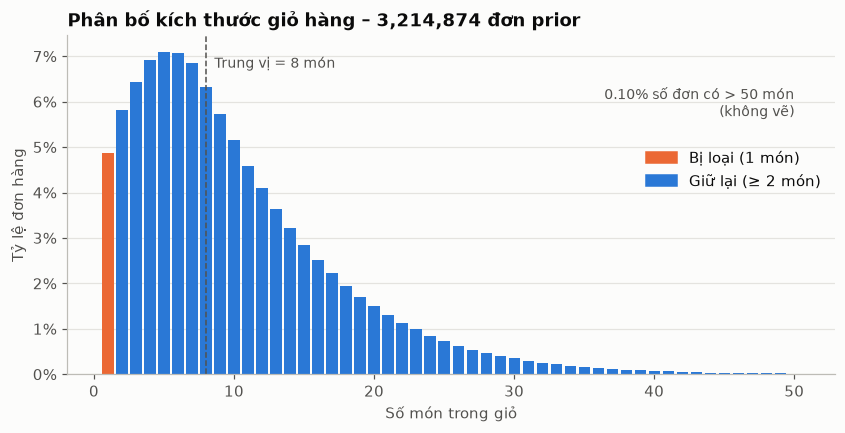

In [5]:
share = basket_size.value_counts(normalize=True).sort_index()
shown = share.loc[1:50]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(shown.index, shown.values, width=0.8,
       color=[ORANGE if k < MIN_BASKET_SIZE else BLUE for k in shown.index])
median = basket_size.median()
ax.axvline(median, color=TEXT_2, lw=1, ls='--')
ax.text(median + 0.6, shown.max() * 0.95, f'Trung vị = {median:.0f} món', color=TEXT_2, fontsize=9)
ax.text(50, shown.max() * 0.80, f'{(basket_size > 50).mean():.2%} số đơn có > 50 món\n(không vẽ)',
        ha='right', color=TEXT_2, fontsize=9)
ax.yaxis.set_major_formatter(pct())
ax.grid(axis='x', visible=False)
ax.set_xlabel('Số món trong giỏ')
ax.set_ylabel('Tỷ lệ đơn hàng')
ax.set_title(f'Phân bố kích thước giỏ hàng – {len(basket_size):,} đơn prior')
ax.legend(handles=[Patch(color=ORANGE, label='Bị loại (1 món)'), Patch(color=BLUE, label='Giữ lại (≥ 2 món)')],
          loc='upper right', bbox_to_anchor=(1, 0.7))
save(fig, '01_basket_size')
plt.show()

**Nhận xét.** Phần lớn giỏ hàng có vài đến khoảng chục món, phân bố lệch phải với đuôi dài.
Đơn 1 món chỉ chiếm một tỷ lệ nhỏ; loại chúng đi không làm mất nhiều dữ liệu, trong khi chúng không thể sinh ra luật `A → B`.
Hệ quả cần nêu trong báo cáo: support được tính trên các giỏ có ≥ 2 món, nên cao hơn một chút so với khi tính trên toàn bộ đơn.

## 4. Sản phẩm phổ biến và hiện tượng "đuôi dài"

Support tổng thể của mỗi sản phẩm = số đơn (≥ 2 món) chứa sản phẩm đó / tổng số đơn (≥ 2 món).

In [6]:
name_of = products.set_index('product_id')['product_name']
pop_counts = op_prior.loc[op_prior['order_id'].isin(eligible), 'product_id'].value_counts()
pop_support = (pop_counts / N_POP).rename(index=name_of).rename_axis('Sản phẩm')

print(f'{len(pop_support):,} sản phẩm xuất hiện trong {N_POP:,} đơn')
(pop_support.head(20) * 100).round(2).rename('Support (%)').to_frame()

49,674 sản phẩm xuất hiện trong 3,058,126 đơn


,Support (%)
Sản phẩm,
Banana,15.39
Bag of Organic Bananas,12.32
Organic Strawberries,8.62
Organic Baby Spinach,7.87
Organic Hass Avocado,6.96
Organic Avocado,5.77
Large Lemon,4.98
Strawberries,4.64
Limes,4.59


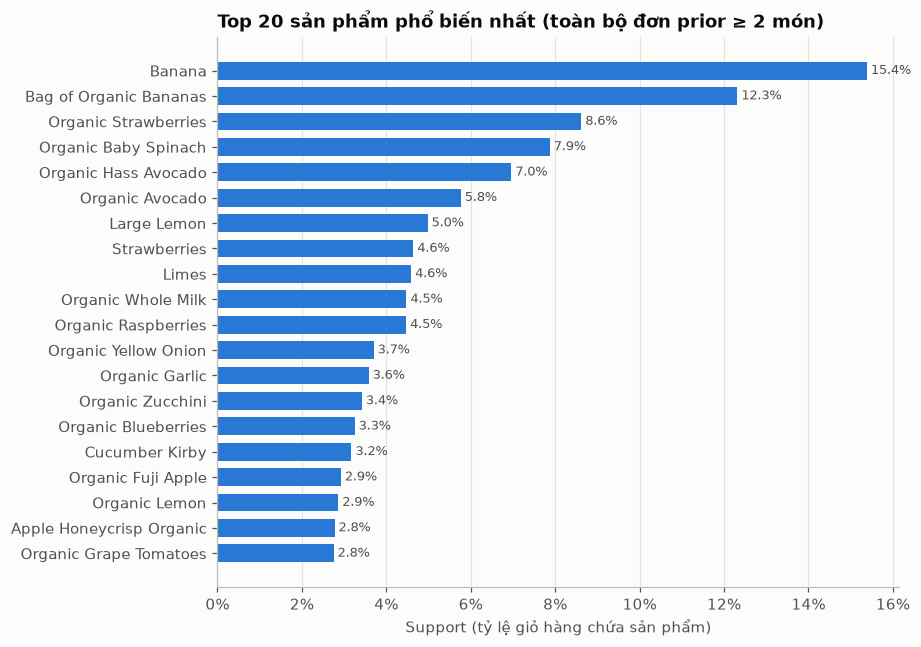

In [7]:
top = pop_support.head(20)[::-1]

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top.index, top.values, height=0.7, color=BLUE)
for y, v in enumerate(top.values):
    ax.text(v, y, f' {v:.1%}', va='center', fontsize=8.5, color=TEXT_2)
ax.xaxis.set_major_formatter(pct())
ax.grid(axis='y', visible=False)
ax.set_xlabel('Support (tỷ lệ giỏ hàng chứa sản phẩm)')
ax.set_title('Top 20 sản phẩm phổ biến nhất (toàn bộ đơn prior ≥ 2 món)')
save(fig, '02_top_products')
plt.show()

Biểu đồ dưới xếp hạng **tất cả** sản phẩm theo support (thang log hai trục). Các đường ngang là các ngưỡng `min_support`
dùng trong benchmark; chỉ những sản phẩm nằm **trên** đường mới có thể xuất hiện trong tập phổ biến.

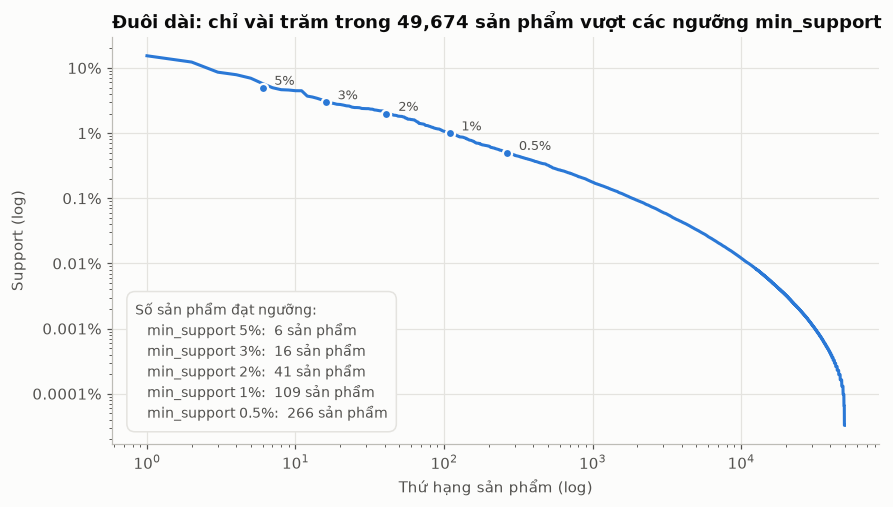

In [8]:
ranks = np.arange(1, len(pop_support) + 1)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.loglog(ranks, pop_support.values, color=BLUE, lw=2)
lines = ['Số sản phẩm đạt ngưỡng:']
for s in SUPPORTS:
    # Điểm giao giữa ngưỡng và đường cong: có n sản phẩm đạt support >= s
    n = (pop_support >= s).sum()
    ax.plot(n, s, 'o', ms=6, color=BLUE, mec=SURFACE, mew=1.5)
    ax.text(n * 1.2, s * 1.1, f'{s * 100:g}%', fontsize=8.5, color=TEXT_2)
    lines.append(f'   min_support {s * 100:g}%:  {n:,} sản phẩm')
ax.text(0.03, 0.05, '\n'.join(lines), transform=ax.transAxes, fontsize=9, color=TEXT_2, va='bottom',
        linespacing=1.5, bbox={'facecolor': SURFACE, 'edgecolor': GRID, 'boxstyle': 'round,pad=0.6'})
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v * 100:g}%'))
ax.set_xlabel('Thứ hạng sản phẩm (log)')
ax.set_ylabel('Support (log)')
ax.set_title(f'Đuôi dài: chỉ vài trăm trong {len(pop_support):,} sản phẩm vượt các ngưỡng min_support')
save(fig, '03_long_tail')
plt.show()

**Nhận xét.** Phân bố support có dạng **đuôi dài**: vài chục sản phẩm rất phổ biến, còn hàng chục nghìn sản phẩm cực hiếm.
Ở ngưỡng 5% chỉ còn một nhúm sản phẩm; mỗi lần hạ ngưỡng, số sản phẩm "sống sót" tăng nhanh, và số **tập ứng viên** của
Apriori tăng theo tổ hợp của con số đó. Đây là cơ sở để dự đoán Apriori chậm đi rõ rệt ở các ngưỡng thấp.

Điều này cũng giải thích vì sao FP-Growth loại món hiếm ngay ở lần duyệt dữ liệu đầu tiên: hơn 99% sản phẩm bị loại mà không làm đổi kết quả.

## 5. Mẫu 10k / 50k / 100k có đại diện cho toàn bộ dữ liệu không?

Đọc 3 file giao dịch đầu ra của tiền xử lý và so sánh với tổng thể (≈ 3 triệu đơn) theo ba góc:
kích thước giỏ, support của các sản phẩm phổ biến, và số sản phẩm vượt từng ngưỡng.

In [9]:
SIZES = ['10k', '50k', '100k']
samples = {s: pd.read_parquet(PROCESSED_DIR / f'transactions_product_{s}.parquet') for s in SIZES}


def item_support(tx):
    """Support của từng item trong một tập giao dịch."""
    return tx['items'].explode().value_counts() / len(tx)


sample_support = {s: item_support(tx) for s, tx in samples.items()}

pd.DataFrame({
    'Số giỏ': [f'{N_POP:,}'] + [f'{len(samples[s]):,}' for s in SIZES],
    'Kích thước giỏ TB': [basket_size[basket_size >= MIN_BASKET_SIZE].mean()] + [samples[s]['item_count'].mean() for s in SIZES],
    'Số sản phẩm phân biệt': [f'{len(pop_support):,}'] + [f'{len(sample_support[s]):,}' for s in SIZES],
}, index=['Tổng thể'] + [f'Mẫu {s}' for s in SIZES]).round(2)

,Số giỏ,Kích thước giỏ TB,Số sản phẩm phân biệt
Tổng thể,"3,058,126",10.55,"49,674"
Mẫu 10k,"10,000",10.62,"16,516"
Mẫu 50k,"50,000",10.60,"29,520"
Mẫu 100k,"100,000",10.56,"35,400"


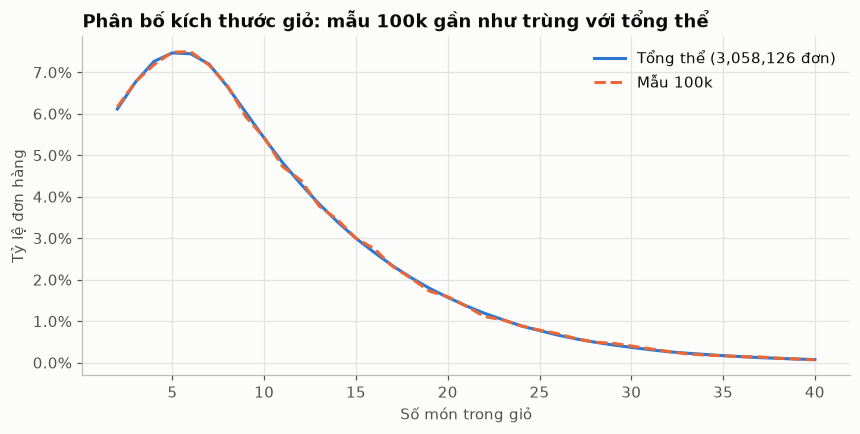

Chênh lệch lớn nhất giữa hai phân bố: 0.10 điểm %


In [10]:
x = np.arange(MIN_BASKET_SIZE, 41)
pop_dist = basket_size[basket_size >= MIN_BASKET_SIZE].value_counts(normalize=True).reindex(x, fill_value=0)
smp_dist = samples['100k']['item_count'].value_counts(normalize=True).reindex(x, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x, pop_dist.values, color=BLUE, lw=2, label=f'Tổng thể ({N_POP:,} đơn)')
ax.plot(x, smp_dist.values, color=ORANGE, lw=2, ls='--', label='Mẫu 100k')
ax.yaxis.set_major_formatter(pct(1))
ax.set_xlabel('Số món trong giỏ')
ax.set_ylabel('Tỷ lệ đơn hàng')
ax.set_title('Phân bố kích thước giỏ: mẫu 100k gần như trùng với tổng thể')
ax.legend()
save(fig, '04_sample_vs_population_basket')
plt.show()
print(f'Chênh lệch lớn nhất giữa hai phân bố: {(pop_dist - smp_dist).abs().max() * 100:.2f} điểm %')

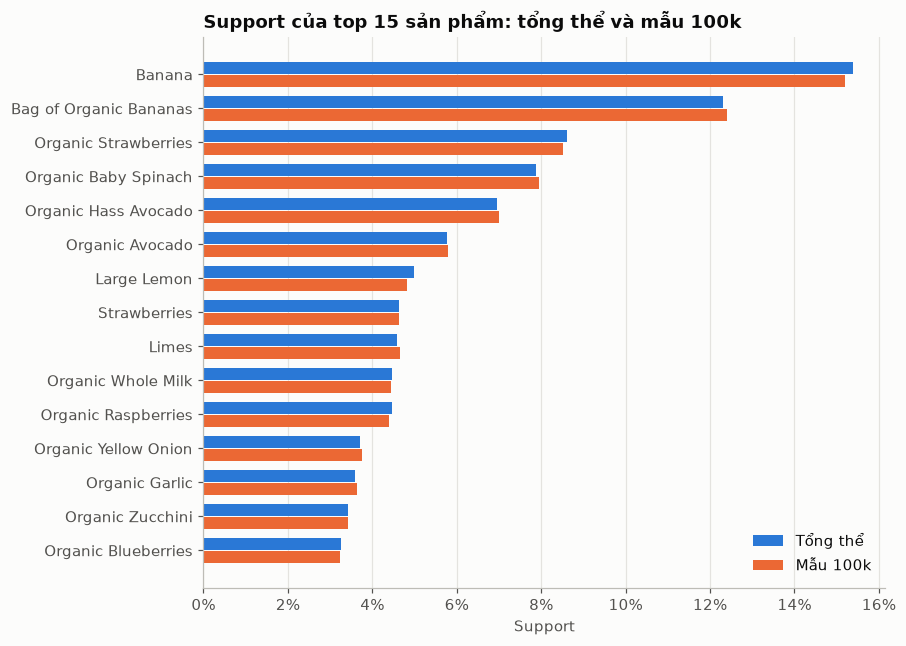

,Tổng thể (%),Mẫu 10k (%),Mẫu 50k (%),Mẫu 100k (%)
Sản phẩm,,,,
Banana,15.39,15.17,15.32,15.20
Bag of Organic Bananas,12.32,12.82,12.61,12.41
Organic Strawberries,8.62,8.82,8.46,8.53
Organic Baby Spinach,7.87,8.61,8.00,7.94
Organic Hass Avocado,6.96,6.51,6.89,7.01
Organic Avocado,5.77,5.82,5.80,5.80
Large Lemon,4.98,5.09,4.90,4.83
Strawberries,4.64,4.85,4.76,4.62
Limes,4.59,5.07,4.80,4.66


In [11]:
TOP_N = 15
cmp = pd.DataFrame({'Tổng thể': pop_support.head(TOP_N)})
for s in SIZES:
    cmp[f'Mẫu {s}'] = sample_support[s].reindex(cmp.index).fillna(0)

fig, ax = plt.subplots(figsize=(8, 6.5))
y = np.arange(TOP_N)[::-1]
h = 0.38
ax.barh(y + h / 2, cmp['Tổng thể'], height=h - 0.04, color=BLUE, label='Tổng thể')
ax.barh(y - h / 2, cmp['Mẫu 100k'], height=h - 0.04, color=ORANGE, label='Mẫu 100k')
ax.set_yticks(y, cmp.index)
ax.xaxis.set_major_formatter(pct())
ax.grid(axis='y', visible=False)
ax.set_xlabel('Support')
ax.set_title(f'Support của top {TOP_N} sản phẩm: tổng thể và mẫu 100k')
ax.legend(loc='lower right')
save(fig, '05_sample_vs_population_top_products')
plt.show()

(cmp * 100).round(2).add_suffix(' (%)')

In [12]:
# Mức độ khớp trên tất cả sản phẩm có support tổng thể >= 0,1%
common = pop_support[pop_support >= 0.001].index
rows = []
for s in SIZES:
    smp = sample_support[s].reindex(common).fillna(0)
    rows.append({
        'Mẫu': s,
        'Số sản phẩm so sánh': len(common),
        'Hệ số tương quan Pearson': np.corrcoef(pop_support[common], smp)[0, 1],
        'Sai lệch tuyệt đối TB (điểm %)': (pop_support[common] - smp).abs().mean() * 100,
        'Sai lệch lớn nhất (điểm %)': (pop_support[common] - smp).abs().max() * 100,
    })
pd.DataFrame(rows).set_index('Mẫu').round(4)

,Số sản phẩm so sánh,Hệ số tương quan Pearson,Sai lệch tuyệt đối TB (điểm %),Sai lệch lớn nhất (điểm %)
Mẫu,,,,
10k,1848,0.9963,0.0432,0.7374
50k,1848,0.9993,0.0190,0.2908
100k,1848,0.9997,0.0131,0.1858


In [13]:
aisle_tx = pd.read_parquet(PROCESSED_DIR / 'transactions_aisle_100k.parquet')
aisle_support = item_support(aisle_tx)

threshold_table = pd.DataFrame({
    'min_support': [f'{s:.1%}' for s in SUPPORTS],
    'Tổng thể': [(pop_support >= s).sum() for s in SUPPORTS],
    **{f'Mẫu {k}': [(sample_support[k] >= s).sum() for s in SUPPORTS] for k in SIZES},
    'Kệ hàng (mẫu 100k)': [(aisle_support >= s).sum() for s in SUPPORTS],
}).set_index('min_support')
threshold_table

,Tổng thể,Mẫu 10k,Mẫu 50k,Mẫu 100k,Kệ hàng (mẫu 100k)
min_support,,,,,
5.0%,6,8,6,6,49
3.0%,16,16,16,16,63
2.0%,41,42,42,41,79
1.0%,109,119,110,108,96
0.5%,266,279,276,269,118


**Nhận xét.** Bảng trên cho biết **số món còn lại sau bước cắt tỉa** ở mỗi ngưỡng, tức số cột của ma trận one-hot mà
Apriori/FP-Growth thực sự phải xử lý (cột `n_items_after_prune` trong kết quả benchmark sẽ khớp với các con số này).
Các mẫu cho số lượng gần với tổng thể; mẫu càng lớn càng sát. Ở ngưỡng thấp, mẫu 10k dao động nhiều hơn vì các món
gần ngưỡng có thể "lọt" lên hoặc xuống do nhiễu lấy mẫu.

Thử nhanh FP-Growth trên mẫu 100k (mức sản phẩm) để xem **các ngưỡng benchmark hiện tại sinh ra bao nhiêu tập phổ biến**,
chia theo độ dài tập. Đây chưa phải benchmark, chỉ để kiểm tra dải ngưỡng có đủ "khó" hay không.

In [14]:
import sys
sys.path.insert(0, str(ROOT / 'src'))
from my_fpgrowth import OptimizedFPGrowth

tx100 = [list(items) for items in samples['100k']['items']]
by_len = {}
for s in SUPPORTS:
    fi = OptimizedFPGrowth(min_support=s).fit(tx100).get_frequent_itemsets()
    by_len[f'{s:.1%}'] = fi['length'].value_counts()
itemset_table = pd.DataFrame(by_len).T.fillna(0).astype(int).rename(columns=lambda k: f'{k} món')
itemset_table.index.name = 'min_support'
itemset_table['Tổng'] = itemset_table.sum(axis=1)
itemset_table

itemsets,1 món,2 món,Tổng
min_support,,,
5.0%,6,0,6
3.0%,16,0,16
2.0%,41,2,43
1.0%,108,18,126
0.5%,269,90,359


## 6. Mức kệ hàng (aisle)

Khi gộp sản phẩm theo kệ, mỗi item phổ biến hơn rất nhiều, nên ở cùng một ngưỡng sẽ có nhiều item và nhiều luật hơn.

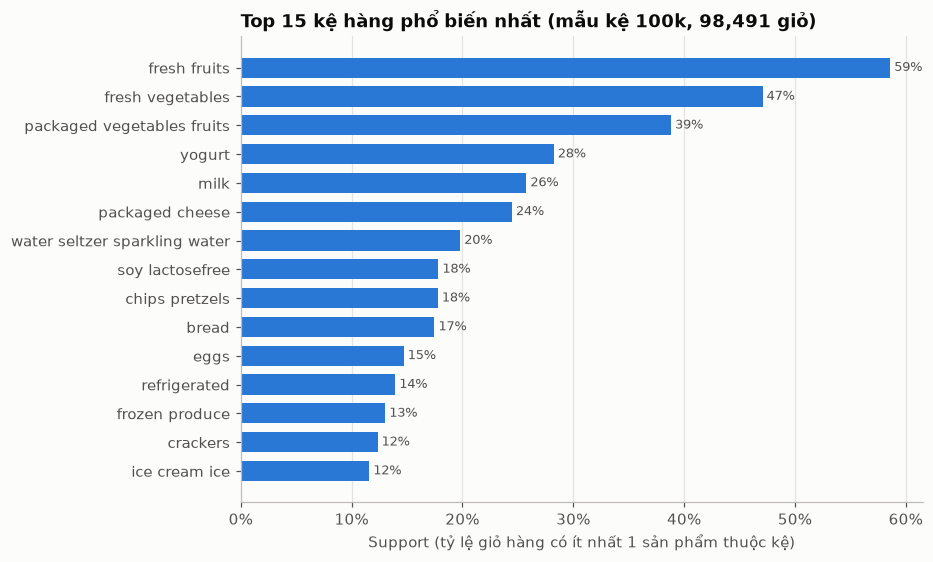

Số kệ: 133 | kích thước giỏ TB theo kệ: 7.67


In [15]:
top_a = aisle_support.head(15)[::-1]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top_a.index, top_a.values, height=0.7, color=BLUE)
for y, v in enumerate(top_a.values):
    ax.text(v, y, f' {v:.0%}', va='center', fontsize=8.5, color=TEXT_2)
ax.xaxis.set_major_formatter(pct())
ax.grid(axis='y', visible=False)
ax.set_xlabel('Support (tỷ lệ giỏ hàng có ít nhất 1 sản phẩm thuộc kệ)')
ax.set_title(f'Top 15 kệ hàng phổ biến nhất (mẫu kệ 100k, {len(aisle_tx):,} giỏ)')
save(fig, '06_top_aisles')
plt.show()

print(f'Số kệ: {len(aisle_support)} | kích thước giỏ TB theo kệ: {aisle_tx["item_count"].mean():.2f}')

## 7. Hạn chế: một khách hàng có thể đóng góp nhiều đơn

Mẫu được lấy theo **đơn hàng**, không theo khách hàng. Nếu một khách có nhiều đơn trong mẫu, thói quen mua lặp lại
của khách đó có thể làm tăng support của một số món.

In [16]:
s100 = samples['100k'][['order_id']].merge(orders[['order_id', 'user_id']], on='order_id')
per_user = s100.groupby('user_id').size()
bucket = per_user.clip(upper=4).map({1: '1 đơn', 2: '2 đơn', 3: '3 đơn', 4: '≥ 4 đơn'})

pd.DataFrame({
    'Số khách': bucket.value_counts(),
    'Tỷ lệ khách (%)': (bucket.value_counts(normalize=True) * 100).round(2),
    'Số đơn trong mẫu': per_user.groupby(bucket).sum(),
}).reindex(['1 đơn', '2 đơn', '3 đơn', '≥ 4 đơn'])

,Số khách,Tỷ lệ khách (%),Số đơn trong mẫu
1 đơn,45900,68.36,45900
2 đơn,13818,20.58,27636
3 đơn,4635,6.90,13905
≥ 4 đơn,2787,4.15,12559


In [17]:
print(f'Mẫu 100k: {len(s100):,} đơn đến từ {len(per_user):,} khách; '
      f'nhiều nhất {per_user.max()} đơn/khách; '
      f'{per_user[per_user > 1].sum() / len(s100):.1%} số đơn thuộc khách có > 1 đơn trong mẫu.')

Mẫu 100k: 100,000 đơn đến từ 67,140 khách; nhiều nhất 10 đơn/khách; 54.1% số đơn thuộc khách có > 1 đơn trong mẫu.


## 8. Kết luận

**Về dữ liệu và các quyết định tiền xử lý**
- Dữ liệu sạch: không có tên sản phẩm rỗng/trùng, không có cặp (đơn, sản phẩm) lặp, không có `product_id` "mồ côi".
  Vấn đề duy nhất là **1.258 sản phẩm thuộc kệ `missing`** (69.145 dòng prior) → đã loại ở mức kệ hàng.
- **4,88%** số đơn prior chỉ có 1 món → bị loại vì không sinh được luật. Còn lại **3.058.126 đơn**.
  Support trong toàn bộ dự án được tính trên các giỏ có ≥ 2 món.
- Giỏ hàng trung vị có 8 món, trung bình ≈ 10, phân bố lệch phải; chỉ 0,10% số đơn có hơn 50 món.

**Về tính đại diện của mẫu**
- Mẫu 100k gần như trùng với tổng thể: phân bố kích thước giỏ lệch tối đa **0,10 điểm %**; support của
  1.848 sản phẩm phổ biến (support ≥ 0,1%) có tương quan **0,9997** và sai lệch trung bình **0,013 điểm %**.
- Mẫu càng lớn càng sát (sai lệch lớn nhất: 0,74 → 0,29 → 0,19 điểm % cho 10k → 50k → 100k).
  Số sản phẩm vượt từng ngưỡng ở mẫu 50k và 100k gần như bằng tổng thể; mẫu 10k dư khoảng 10 sản phẩm ở ngưỡng 1% và 0,5% do nhiễu lấy mẫu.

**Về khai phá và benchmark**
- Support có dạng **đuôi dài**: món phổ biến nhất là Banana (15,4%), nhưng chỉ **6** sản phẩm đạt 5%, **109** đạt 1% và **266** đạt 0,5%
  trên tổng số 49.674 sản phẩm. Số món sau cắt tỉa tăng nhanh khi hạ ngưỡng → dự đoán Apriori chậm hẳn ở các ngưỡng thấp.
- **Dải ngưỡng benchmark hiện tại quá "dễ" ở mức sản phẩm.** Trên mẫu 100k: ngưỡng 5% và 3% không có tập 2 món nào;
  2% có 2 cặp, 1% có 18 cặp, 0,5% có 90 cặp, và **không có tập 3 món nào** ở mọi ngưỡng (cặp mạnh nhất chỉ đạt 2,06%).
  Với chừng đó tập phổ biến, cả Apriori lẫn FP-Growth đều chạy rất nhanh và khó thấy khác biệt.
  → Nên mở rộng benchmark xuống các ngưỡng thấp hơn (ví dụ 0,3%, 0,2%, 0,1%), hoặc benchmark thêm trên dữ liệu mức kệ hàng.
- Ở mức kệ hàng, item phổ biến hơn nhiều (fresh fruits 59%, fresh vegetables 47%): 49 kệ đạt 5% → phù hợp để tìm luật
  ở các ngưỡng cao.
- Một số "sản phẩm" là biến thể của nhau (Banana / Bag of Organic Bananas, Organic Hass Avocado / Organic Avocado),
  nên support bị chia nhỏ. Mức kệ hàng phần nào bù lại hạn chế này.

**Hạn chế cần nêu trong báo cáo**
- Mẫu lấy theo đơn: 100k đơn đến từ 67.140 khách; 54,1% số đơn thuộc khách có > 1 đơn trong mẫu (tối đa 10 đơn/khách).
  Thói quen mua lặp lại của cùng một khách có thể làm tăng support của một số món.